In [84]:
import pandas as pd 
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns 

# load dataset 

In [85]:
data=pd.read_csv(r"C:\Users\text\Downloads\netflix_titles.csv\netflix_titles.csv")

In [86]:
data.info()
# 1 dtype 
# nan value 


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [87]:
# only using numarical columns 
data.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [88]:
# droping rating columns 
data.drop(columns = "rating",inplace=True)

In [89]:
# duplicated value not inside dataset 
data.drop_duplicates(inplace  =True)

# droping nan values 

In [90]:
# nan valuse inside in dataset and deleted all nan values 1 
data.isna().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
duration           3
listed_in          0
description        0
dtype: int64

In [91]:
data.dropna(inplace = True)

# rename columns 

In [92]:
new_columns=[]
for i in data.columns:
    new_columns.append(i.capitalize())

In [93]:
new_columns

['Show_id',
 'Type',
 'Title',
 'Director',
 'Cast',
 'Country',
 'Date_added',
 'Release_year',
 'Duration',
 'Listed_in',
 'Description']

In [94]:
data.columns  = new_columns

In [95]:
data

,Show_id,Type,Title,Director,Cast,Country,Date_added,Release_year,Duration,Listed_in,Description
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
24,s25,Movie,Jeans,S. Shankar,"Prashanth, Aishwarya Rai Bachchan, Sri Lakshmi...",India,"September 21, 2021",1998,166 min,"Comedies, International Movies, Romantic Movies",When the father of the man she loves insists t...
...,...,...,...,...,...,...,...,...,...,...,...
8801,s8802,Movie,Zinzana,Majid Al Ansari,"Ali Suliman, Saleh Bakri, Yasa, Ali Al-Jabri, ...","United Arab Emirates, Jordan","March 9, 2016",2015,96 min,"Dramas, International Movies, Thrillers",Recovering alcoholic Talal wakes up inside a s...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [96]:
data["Show_id"].unique()

array(['s8', 's9', 's10', ..., 's8805', 's8806', 's8807'],
      shape=(5333,), dtype=object)

## check for some transformations

In [97]:
# removing for ( s )
data["Show_id"].apply(lambda x:x.split("s")[1])

7          8
8          9
9         10
12        13
24        25
        ... 
8801    8802
8802    8803
8804    8805
8805    8806
8806    8807
Name: Show_id, Length: 5333, dtype: object

In [81]:
# origanl dataset not change for show_id 
data

,Show_id,Type,Title,Director,Cast,Country,Date_added,Release_year,Duration,Listed_in,Description
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
24,s25,Movie,Jeans,S. Shankar,"Prashanth, Aishwarya Rai Bachchan, Sri Lakshmi...",India,"September 21, 2021",1998,166 min,"Comedies, International Movies, Romantic Movies",When the father of the man she loves insists t...
...,...,...,...,...,...,...,...,...,...,...,...
8801,s8802,Movie,Zinzana,Majid Al Ansari,"Ali Suliman, Saleh Bakri, Yasa, Ali Al-Jabri, ...","United Arab Emirates, Jordan","March 9, 2016",2015,96 min,"Dramas, International Movies, Thrillers",Recovering alcoholic Talal wakes up inside a s...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [102]:
# change for origanile data
data["Show_id"]=data["Show_id"].apply(lambda x:x.split("s")[1])

In [106]:
data["Show_id"]=data["Show_id"].astype(int)

# change for data_added

In [107]:
# not removing for space 
data["Date_added"][54]

'September 15, 2021'

In [108]:
# 1. Check the exact value before stripping
print(repr(data["Date_added"].iloc[1177]))

# 2. Remove leading/trailing spaces
data["Date_added"] = data["Date_added"].astype(str).str.strip()

# 3. Check again
print(repr(data["Date_added"].iloc[1177]))

'July 8, 2020'
'July 8, 2020'


In [109]:
data["Date_added"]=pd.to_datetime(data["Date_added"])

In [110]:
data

,Show_id,Type,Title,Director,Cast,Country,Date_added,Release_year,Duration,Listed_in,Description
7,8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,2021-09-24,2021,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,2021-09-24,2021,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...
12,13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic",2021-09-23,2021,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
24,25,Movie,Jeans,S. Shankar,"Prashanth, Aishwarya Rai Bachchan, Sri Lakshmi...",India,2021-09-21,1998,166 min,"Comedies, International Movies, Romantic Movies",When the father of the man she loves insists t...
...,...,...,...,...,...,...,...,...,...,...,...
8801,8802,Movie,Zinzana,Majid Al Ansari,"Ali Suliman, Saleh Bakri, Yasa, Ali Al-Jabri, ...","United Arab Emirates, Jordan",2016-03-09,2015,96 min,"Dramas, International Movies, Thrillers",Recovering alcoholic Talal wakes up inside a s...
8802,8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8804,8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


# Find outlier 

<Axes: ylabel='Release_year'>

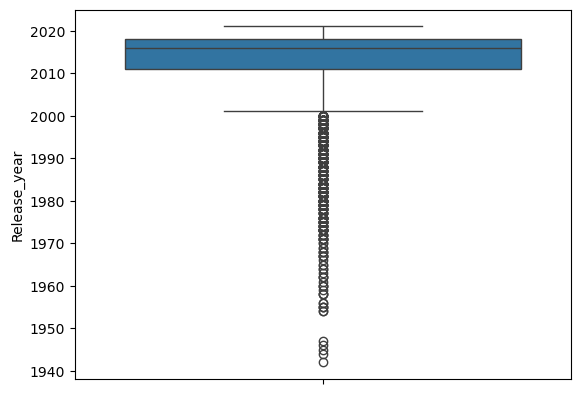

In [111]:
# the data inside outler but not removing because this is importent data 
sns.boxplot(data["Release_year"])

In [112]:
# releases year year
data["Release_year"].min()

1942

In [113]:
# and persent value year 
data["Release_year"].max()


2021

In [114]:
# minuman values 
data["Duration"].min()

'1 Season'

In [115]:
# maximum values 
data["Duration"].max()

'99 min'

In [117]:
# cleaning for netflix datset 
data.to_csv("cleaning data for netflix_dataset.csv",index= False)

,Show_id,Type,Title,Director,Cast,Country,Date_added,Release_year,Duration,Listed_in,Description
0,8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
1,9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,2021-09-24,2021,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
2,10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,2021-09-24,2021,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...
3,13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic",2021-09-23,2021,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
4,25,Movie,Jeans,S. Shankar,"Prashanth, Aishwarya Rai Bachchan, Sri Lakshmi...",India,2021-09-21,1998,166 min,"Comedies, International Movies, Romantic Movies",When the father of the man she loves insists t...
...,...,...,...,...,...,...,...,...,...,...,...
5328,8802,Movie,Zinzana,Majid Al Ansari,"Ali Suliman, Saleh Bakri, Yasa, Ali Al-Jabri, ...","United Arab Emirates, Jordan",2016-03-09,2015,96 min,"Dramas, International Movies, Thrillers",Recovering alcoholic Talal wakes up inside a s...
5329,8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
5330,8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
5331,8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
